<a href="https://colab.research.google.com/github/L66380/new-customer-discount-ab-test/blob/main/new_customer_discount_ab_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## A/B Testing: 10% Discount for New Customers

**Research Question:** Does offering a 10% discount to new customers increase purchase conversion rates?

**Hypothesis:** New customers receiving a 10% discount will have a higher purchase conversion rate than customers receiving no discount.

**Group A:** No discount (Control)

**Group B:** 10% discount (Treatment)

**Primary Metric:** Purchase conversion rate.

**Data:** Simulated customer data, not a real-world experiment.

In [26]:

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
import math

# Assumptions for planning the experiment
baseline_rate = 0.08
target_rate = 0.12
alpha = 0.05
power = 0.80
daily_new_customers = 100  # Assumed daily traffic

effect_size = proportion_effectsize(
    baseline_rate, target_rate
)

analysis = NormalIndPower()

sample_per_group = math.ceil(
    analysis.solve_power(
        effect_size=effect_size,
        alpha=alpha,
        power=power,
        ratio=1,
        alternative="two-sided"
    )
)

total_sample = sample_per_group * 2
duration = math.ceil(total_sample / daily_new_customers)

print("Required sample per group:", sample_per_group)
print("Total required sample:", total_sample)
print("Estimated duration (days):", duration)


Required sample per group: 875
Total required sample: 1750
Estimated duration (days): 18


## Sample Size and Duration

The required sample size is 875 customers per group (1,750 total), based on 80% statistical power and a 5% significance level.

Assuming 100 new customers per day, the estimated experiment duration is 18 days.

The simulation uses 1,750 customers, matching the calculated total sample size, with approximately equal random allocation between groups.

In [27]:

import numpy as np
import pandas as pd
from scipy import stats

np.random.seed(42)



In [28]:

# Simulate an A/B test for new customers
n = 1750

df = pd.DataFrame({
    "customer_id": range(1, n + 1),
    "group": np.random.choice(["A", "B"], size=n)
})

# A = No discount
# B = 10% discount
df["discount"] = np.where(df["group"] == "B", 10, 0)

df.head(10)


,customer_id,group,discount
0,1,A,0
1,2,B,10
2,3,A,0
3,4,A,0
4,5,A,0
5,6,B,10
6,7,A,0
7,8,A,0
8,9,A,0
9,10,B,10


In [29]:

# Simulated purchase probabilities
# A: 8% without discount
# B: 12% with discount

df["purchased"] = np.where(
    df["group"] == "A",
    np.random.binomial(1, 0.08, len(df)),
    np.random.binomial(1, 0.12, len(df))
)

df.head(10)


,customer_id,group,discount,purchased
0,1,A,0,0
1,2,B,10,0
2,3,A,0,0
3,4,A,0,0
4,5,A,0,0
5,6,B,10,0
6,7,A,0,0
7,8,A,0,0
8,9,A,0,0
9,10,B,10,0


## Analysis Plan

The primary metric is purchase conversion rate. The analysis compares Group A (no discount) and Group B (10% discount) using a Chi-Square test at a 5% significance level.

The analysis also includes a Sample Ratio Mismatch (SRM) check and a 95% confidence interval for the difference in conversion rates.

If the p-value is below 0.05, the difference will be considered statistically significant. Results are based on simulated data.

## Guardrail Metrics

The main guardrail metric is profit per customer, to ensure the 10% discount does not reduce profitability.

Profit data is not available in this simulation, so this metric cannot be evaluated.

In [30]:

results = df.groupby("group").agg(
    customers=("customer_id", "count"),
    purchases=("purchased", "sum"),
    conversion_rate=("purchased", "mean")
)

results["conversion_rate"] *= 100

print(results)


       customers  purchases  conversion_rate
group                                       
A            885         79         8.926554
B            865        107        12.369942


In [31]:

from scipy.stats import chi2_contingency

table = pd.crosstab(df["group"], df["purchased"])

chi2, p_value, dof, expected = chi2_contingency(
    table, correction=False
)

print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Statistically significant difference")
else:
    print("No statistically significant difference")


P-value: 0.0195
Statistically significant difference


In [32]:

from scipy.stats import chisquare

group_counts = df["group"].value_counts().reindex(["A", "B"])
expected_counts = [len(df) / 2, len(df) / 2]

srm_stat, srm_p_value = chisquare(
    f_obs=group_counts,
    f_exp=expected_counts
)

print("Group counts:")
print(group_counts)
print("SRM P-value:", round(srm_p_value, 4))

if srm_p_value < 0.001:
    print("Potential SRM detected")
else:
    print("No evidence of SRM")


Group counts:
group
A    885
B    865
Name: count, dtype: int64
SRM P-value: 0.6326
No evidence of SRM


In [33]:

import numpy as np

# Conversion rates
rate_a = results.loc["A", "conversion_rate"] / 100
rate_b = results.loc["B", "conversion_rate"] / 100

n_a = results.loc["A", "customers"]
n_b = results.loc["B", "customers"]

# Difference in conversion rates
difference = rate_b - rate_a

# Standard error
se = np.sqrt(
    rate_a * (1 - rate_a) / n_a +
    rate_b * (1 - rate_b) / n_b
)

# 95% confidence interval
ci_lower = difference - 1.96 * se
ci_upper = difference + 1.96 * se

print("Conversion rate difference:", round(difference * 100, 2), "percentage points")
print("95% Confidence Interval:",
      (round(ci_lower * 100, 2), round(ci_upper * 100, 2)))


Conversion rate difference: 3.44 percentage points
95% Confidence Interval: (np.float64(0.55), np.float64(6.33))


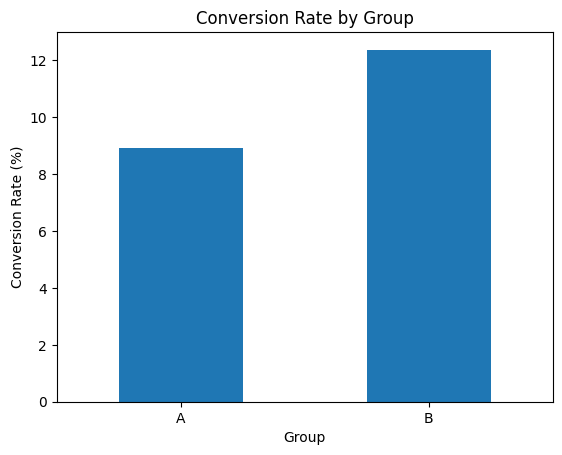

In [34]:

import matplotlib.pyplot as plt

results["conversion_rate"].plot(
    kind="bar",
    title="Conversion Rate by Group",
    ylabel="Conversion Rate (%)",
    xlabel="Group",
    rot=0
)

plt.show()


**Conclusion**

Group B achieved a higher purchase conversion rate (12.37%) compared to Group A (8.93%). The difference was statistically significant (p = 0.0195). These results are based on simulated data and do not establish a real-world business impact. Further validation with real customer data is recommended.

## Final Report

**Objective:** Evaluate whether a 10% discount increases purchase conversion among new customers.

**Sample:** 1,750 simulated customers (885 in Group A and 865 in Group B).

**Results:** Group A achieved 8.93% conversion, compared with 12.37% for Group B, an increase of 3.44 percentage points.

**Statistical Analysis:** The difference was statistically significant (p = 0.0195). The 95% confidence interval was 0.55 to 6.33 percentage points. The SRM test showed no evidence of a randomization imbalance (p = 0.6326).

**Recommendation:** Test the discount with real customers before implementing it. Profitability should also be evaluated because the simulated data does not include profit information.